In [1]:
%pip install -q tiktoken datasets transformers matplotlib tqdm
import os
import math
import time
import random
import gc
from pathlib import Path
from array import array

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import tiktoken

from datasets import load_dataset
from tqdm.auto import tqdm
from transformers import GPT2LMHeadModel

torch.manual_seed(1337)
torch.cuda.manual_seed_all(1337)
np.random.seed(1337)
random.seed(1337)

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_type = "cuda" if torch.cuda.is_available() else "cpu"

project_dir = Path("/content/gpt2_project")
data_dir = project_dir / "fineweb_shards"
log_path = project_dir / "training.log"
checkpoint_path = project_dir / "checkpoint.pt"
graph_path = project_dir / "loss_graph.png"

project_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)
print(f"Device: {device} ({device_type})")

Device: cuda (cuda)


In [2]:
enc = tiktoken.get_encoding("gpt2")
eot_token = enc.eot_token
real_vocab_size = enc.n_vocab

train_tokens = 55_000_000
val_tokens = 2_000_000
shard_tokens = 500_000
val_skip_docs = 2_000_000

print("Vocab size:", real_vocab_size)

Vocab size: 50257


In [3]:
def write_fineweb_shards(split_name, target_tokens, skip_docs=0):
    for old_file in data_dir.glob(f"{split_name}_*.npy"):
        old_file.unlink()

    dataset = load_dataset(
        "HuggingFaceFW/fineweb-edu",
        name="sample-10BT",
        split="train",
        streaming=True
    )

    if skip_docs > 0:
        dataset = dataset.skip(skip_docs)

    buffer = array("H")
    token_count = 0
    doc_count = 0
    shard_index = 0

    for example in tqdm(dataset, desc=f"Writing {split_name} shards"):
        text = example.get("text", "")
        if not text:
            continue

        tokens = enc.encode_ordinary(text)
        buffer.append(eot_token)
        buffer.extend(tokens)

        token_count += len(tokens) + 1
        doc_count += 1

        if len(buffer) >= shard_tokens:
            shard_path = data_dir / f"{split_name}_{shard_index:03d}.npy"
            np.save(shard_path, np.frombuffer(buffer, dtype=np.uint16))
            buffer = array("H")
            shard_index += 1

        if token_count >= target_tokens:
            break

    if len(buffer) > 0:
        shard_path = data_dir / f"{split_name}_{shard_index:03d}.npy"
        np.save(shard_path, np.frombuffer(buffer, dtype=np.uint16))

    del dataset
    del buffer
    return doc_count, token_count

train_doc_count, actual_train_tokens = write_fineweb_shards(
    split_name="train", target_tokens=train_tokens, skip_docs=0
)
val_doc_count, actual_val_tokens = write_fineweb_shards(
    split_name="val", target_tokens=val_tokens, skip_docs=val_skip_docs
)

print(f"Train docs: {train_doc_count}, tokens: {actual_train_tokens}")
print(f"Val docs: {val_doc_count}, tokens: {actual_val_tokens}")
assert train_doc_count < val_skip_docs, "Overlap error in val_skip_docs!"

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Writing train shards: 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Writing val shards: 0it [00:00, ?it/s]

Train docs: 52193, tokens: 55001299
Val docs: 1886, tokens: 2000051


In [4]:
block_size = 512
batch_size = 8
total_batch_tokens = 65_536
accum_steps = total_batch_tokens // (block_size * batch_size)
assert accum_steps * block_size * batch_size == total_batch_tokens

train_files = sorted(data_dir.glob("train_*.npy"))
val_files = sorted(data_dir.glob("val_*.npy"))

assert len(train_files) > 0, "Train shard dosyaları bulunamadı!"
assert len(val_files) > 0, "Validation shard dosyaları bulunamadı!"

class SequentialShardLoader:
    def __init__(self, files, batch_size, block_size, device):
        self.files = files
        self.batch_size = batch_size
        self.block_size = block_size
        self.device = device
        self.shard_index = 0
        self.position = 0
        self.data = None
        self.load_shard()

    def load_shard(self):
        self.data = np.load(self.files[self.shard_index])
        self.position = 0

    def next_batch(self):
        x_batch = np.empty((self.batch_size, self.block_size), dtype=np.int64)
        y_batch = np.empty((self.batch_size, self.block_size), dtype=np.int64)

        for i in range(self.batch_size):
            start = self.position
            end = start + self.block_size + 1

            if end > len(self.data):
                self.shard_index = (self.shard_index + 1) % len(self.files)
                self.load_shard()
                start = 0
                end = self.block_size + 1

            chunk = self.data[start:end]
            x_batch[i] = chunk[:-1]
            y_batch[i] = chunk[1:]
            self.position = end - 1

        x = torch.from_numpy(x_batch).to(self.device)
        y = torch.from_numpy(y_batch).to(self.device)
        return x, y

    def reset(self):
        self.shard_index = 0
        self.load_shard()

train_loader = SequentialShardLoader(train_files, batch_size=batch_size, block_size=block_size, device=device)
val_loader = SequentialShardLoader(val_files, batch_size=batch_size, block_size=block_size, device=device)
print("Loader'lar başarıyla oluşturuldu.")

Loader'lar başarıyla oluşturuldu.


In [5]:
config = {
    "vocab_size": 50304,
    "n_positions": 512,
    "n_embd": 768,
    "n_layer": 12,
    "n_head": 12,
    "layer_norm_epsilon": 1e-5,
    "embd_pdrop": 0.0,
}
print("Config:", config)

Config: {'vocab_size': 50304, 'n_positions': 512, 'n_embd': 768, 'n_layer': 12, 'n_head': 12, 'layer_norm_epsilon': 1e-05, 'embd_pdrop': 0.0}


In [6]:
class GPT2Attention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.num_heads = config["n_head"]
        self.head_dim = config["n_embd"] // self.num_heads
        self.n_embd = config["n_embd"]
        self.c_attn = nn.Linear(self.n_embd, 3 * self.n_embd)
        self.c_proj = nn.Linear(self.n_embd, self.n_embd)
        self.c_proj.RESIDUAL_PROJECTION = True

    def forward(self, x):
        batch_size, seq_len, channels = x.shape
        q, k, v = self.c_attn(x).split(channels, dim=2)
        def split_heads(tensor):
            return tensor.view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        q = split_heads(q)
        k = split_heads(k)
        v = split_heads(v)
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        out = out.transpose(1, 2).contiguous().view(batch_size, seq_len, channels)
        return self.c_proj(out)

class GPT2MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        n_embd = config["n_embd"]
        self.c_fc = nn.Linear(n_embd, 4 * n_embd)
        self.c_proj = nn.Linear(4 * n_embd, n_embd)
        self.c_proj.RESIDUAL_PROJECTION = True

    def forward(self, x):
        x = self.c_fc(x)
        x = F.gelu(x, approximate="tanh")
        x = self.c_proj(x)
        return x

class GPT2Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config["n_embd"], eps=config["layer_norm_epsilon"])
        self.attn = GPT2Attention(config)
        self.ln_2 = nn.LayerNorm(config["n_embd"], eps=config["layer_norm_epsilon"])
        self.mlp = GPT2MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class MyGPT2(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.wte = nn.Embedding(config["vocab_size"], config["n_embd"])
        self.wpe = nn.Embedding(config["n_positions"], config["n_embd"])
        self.drop = nn.Dropout(config["embd_pdrop"])
        self.h = nn.ModuleList([GPT2Block(config) for _ in range(config["n_layer"])])
        self.ln_f = nn.LayerNorm(config["n_embd"], eps=config["layer_norm_epsilon"])
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if getattr(module, "RESIDUAL_PROJECTION", False):
                std /= math.sqrt(2 * self.config["n_layer"])
            nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, idx):
        batch_size, seq_len = idx.shape
        if seq_len > self.config["n_positions"]:
            raise ValueError(f"Sequence length {seq_len} exceeds max {self.config['n_positions']}")
        pos = torch.arange(seq_len, device=idx.device).unsqueeze(0)
        x = self.wte(idx) + self.wpe(pos)
        x = self.drop(x)
        for block in self.h:
            x = block(x)
        x = self.ln_f(x)
        logits = F.linear(x, self.wte.weight)
        return logits

    def configure_optimizers(self, weight_decay=0.1, learning_rate=6e-4, betas=(0.9, 0.95), eps=1e-8):
        decay_params = [p for p in self.parameters() if p.requires_grad and p.dim() >= 2]
        no_decay_params = [p for p in self.parameters() if p.requires_grad and p.dim() < 2]
        param_groups = [
            {"params": decay_params, "weight_decay": weight_decay},
            {"params": no_decay_params, "weight_decay": 0.0},
        ]
        use_fused = (device.type == "cuda" and "fused" in torch.optim.AdamW.__init__.__code__.co_varnames)
        optimizer = torch.optim.AdamW(param_groups, lr=learning_rate, betas=betas, eps=eps, fused=use_fused)
        return optimizer

In [7]:
model = MyGPT2(config).to(device)
optimizer = model.configure_optimizers(weight_decay=0.1, learning_rate=6e-4)
scaler = torch.cuda.amp.GradScaler(enabled=(device_type == "cuda"))
if hasattr(torch, "compile") and device_type == "cuda":
    try:
        training_model = torch.compile(model)
        print("torch.compile başarıyla ayrı bir training_model değişkenine uygulandı.")
    except Exception as e:
        print("torch.compile uygulanamadı, varsayılan model kullanılacak:", e)
        training_model = model
else:
    training_model = model

/tmp/ipykernel_1825/514934777.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device_type == "cuda"))


torch.compile(model) başarıyla ayrı bir training_model değişkenine uygulandı.


In [8]:
@torch.no_grad()
def estimate_val_loss(eval_model, loader, batches=26):
    eval_model.eval()
    losses = []
    loader.reset()
    for _ in range(batches):
        x, y = loader.next_batch()
        with torch.autocast(device_type=device_type, dtype=torch.float16, enabled=(device_type == "cuda")):
            logits = eval_model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        losses.append(loss.item())
    eval_model.train()
    return sum(losses) / len(losses)

@torch.no_grad()
def generate_text(eval_model, prompt, max_new_tokens=80, temperature=0.8, top_k=50, seed=42):
    was_training = eval_model.training
    eval_model.eval()
    generator = torch.Generator(device=device.type)
    generator.manual_seed(seed)

    tokens = enc.encode_ordinary(prompt)
    idx = torch.tensor([tokens], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -config["n_positions"]:]
        with torch.autocast(device_type=device_type, dtype=torch.float16, enabled=(device_type == "cuda")):
            logits = eval_model(idx_cond)
        logits = logits[:, -1, :50257] / temperature

        if top_k is not None:
            values, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            threshold = values[:, -1, None]
            logits = logits.masked_fill(logits < threshold, float("-inf"))

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1, generator=generator)
        idx = torch.cat([idx, next_token], dim=1)
        if next_token.item() == eot_token:
            break

    result = enc.decode(idx[0].tolist())
    eval_model.train(was_training)
    return result

In [9]:
max_steps = 800
warmup_steps = 40
max_lr = 6e-4
min_lr = 6e-5
max_grad_norm = 1.0
eval_interval = 50

def get_lr(step):
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    if step >= max_steps:
        return min_lr
    decay_ratio = (step - warmup_steps) / (max_steps - warmup_steps)
    coefficient = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return min_lr + coefficient * (max_lr - min_lr)

In [10]:
train_loader.reset()
training_model.train()

train_losses = []
val_losses = []
val_steps = []
tok_per_sec_list = []
start_time_total = time.time()
print("Eğitim başlıyor...")

with open(log_path, "w") as f:
    f.write("step,train_loss,val_loss,lr\n")

for step in range(max_steps):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0

    for micro_step in range(accum_steps):
        x, y = train_loader.next_batch()
        with torch.autocast(device_type=device_type, dtype=torch.float16, enabled=(device_type == "cuda")):
            logits = training_model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            loss = loss / accum_steps
        loss_accum += loss.detach().item()
        scaler.scale(loss).backward()

    scaler.unscale_(optimizer)
    norm = torch.nn.utils.clip_grad_norm_(training_model.parameters(), max_grad_norm)
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    scaler.step(optimizer)
    scaler.update()
    if device_type == "cuda":
        torch.cuda.synchronize()
    t1 = time.time()

    dt = t1 - t0
    tokens_per_sec = total_batch_tokens / dt if dt > 0 else 0.0
    tok_per_sec_list.append(tokens_per_sec)
    train_losses.append(loss_accum)

    print(f"Step {step:4d} | Loss: {loss_accum:.4f} | LR: {lr:.6f} | Norm: {norm:.4f} | dt: {dt*1000:.2f}ms | tok/s: {tokens_per_sec:.2f}")
    if step % eval_interval == 0 or step == max_steps - 1:
        val_loss = estimate_val_loss(model, val_loader, batches=26)
        val_losses.append(val_loss)
        val_steps.append(step)
        print(f"---> Step {step:4d} | Validation Loss: {val_loss:.4f}")

        sample_out = generate_text(model, "Artificial intelligence is", max_new_tokens=80, seed=42)
        print(f"[Sample @ Step {step}]:\n{sample_out}\n" + "-"*50)

        with open(log_path, "a") as f:
            f.write(f"{step},{loss_accum:.4f},{val_loss:.4f},{lr:.6f}\n")
            f.write(f"# Sample Step {step}: {sample_out.replace('\n', ' ')}\n")

    if step > 0 and step % 200 == 0:
        ckpt = {
            'step': step,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'config': config,
        }
        torch.save(ckpt, checkpoint_path)
        print(f"[Checkpoint] checkpoint.pt üzerine başarıyla güncellendi (Step {step}).")

total_training_time = time.time() - start_time_total

Eğitim başlıyor...


W1108 11:58:27.159000 1825 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


Step    0 | Loss: 11.0088 | LR: 0.000015 | Norm: 15.2150 | dt: 43129.52ms | tok/s: 1519.52
---> Step    0 | Validation Loss: 10.4093
[Sample @ Step 0]:
Artificial intelligence is legislature the Prismschild herboff the really absorbed Depot Prism Airlines Ord sill changVO diedarlane Simon Enterprises teethsomeoneiator Which the ® Hang,ighthiferiator ;) Coil Muss slain voltageachoPrinc thrive. lithium ;) ADHD tree slainemptyEndormons assorted entertained Triangle,,, Enterprises jugg. mentality Aether.,..avor devil devil 465 Feinstein stars,, jugg Nato,, Enterprises. Enterprises airbg
--------------------------------------------------
Step    1 | Loss: 10.3967 | LR: 0.000030 | Norm: 8.7970 | dt: 3013.07ms | tok/s: 21750.58
Step    2 | Loss: 9.9910 | LR: 0.000045 | Norm: 5.1404 | dt: 3005.68ms | tok/s: 21804.02
Step    3 | Loss: 9.8024 | LR: 0.000060 | Norm: 3.6335 | dt: 3009.11ms | tok/s: 21779.21
Step    4 | Loss: 9.6619 | LR: 0.000075 | Norm: 2.9527 | dt: 3023.35ms | tok/s: 21676.62
St

EĞİTİM ÖZETİ
İşlenen Toplam Token: 52,428,800
Ortalama Hiz (tok/s): 19168.75
Toplam Eğitim Süresi: 2914.62 saniye (48.58 dakika)


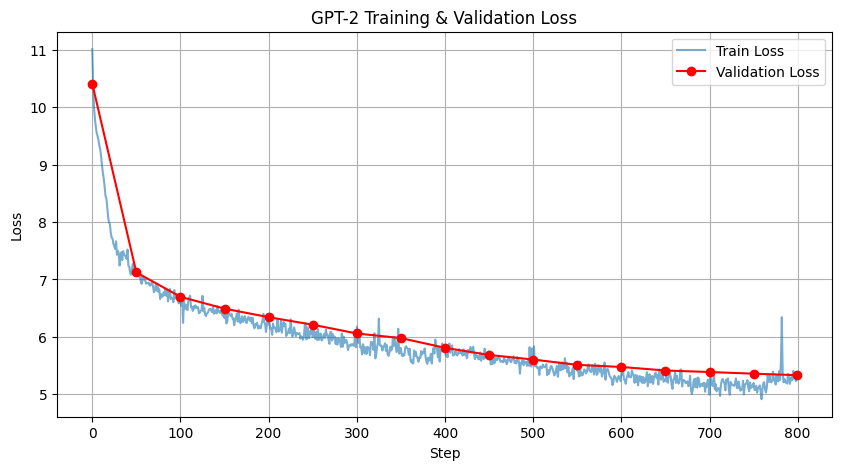


--- Final Örnek Metin Üretimleri ---
Prompt: Artificial intelligence is
Generated: Artificial intelligence is designed to be used in the modern world. It is able to find the technology and not all the best to help people all be able to know and see themselves in such a new world.
One of the time it has been told to a high amount of natural resources that are now available and accessible and easy to learn how to get your family members of their families.
The public is in many
----------------------------------------
Prompt: The future of deep learning
Generated: The future of deep learning for the Internet that is being the same and a nation. When an article, it could be done with the internet to all public and security.
Some of the United States are under the world's most successful, and has an organization to provide access to new financial systems that are now available and accessible to them. In other countries, more than 200,000 people with the state is being in many
-------------

In [11]:
total_tokens_processed = max_steps * total_batch_tokens
avg_tok_per_sec = sum(tok_per_sec_list) / len(tok_per_sec_list) if tok_per_sec_list else 0.0

print("="*50)
print("EĞİTİM ÖZETİ")
print(f"İşlenen Toplam Token: {total_tokens_processed:,}")
print(f"Ortalama Hiz (tok/s): {avg_tok_per_sec:.2f}")
print(f"Toplam Eğitim Süresi: {total_training_time:.2f} saniye ({total_training_time/60:.2f} dakika)")
print("="*50)

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss", alpha=0.6)
plt.plot(val_steps, val_losses, "ro-", label="Validation Loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("GPT-2 Training & Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(graph_path)
plt.show()

prompts = [
    "Artificial intelligence is",
    "The future of deep learning",
    "Once upon a time in a distant world,",
    "In the field of computer science,"
]
print("\n--- Final Örnek Metin Üretimleri ---")
for p in prompts:
    generated = generate_text(model, p, max_new_tokens=80, seed=42)
    print(f"Prompt: {p}")
    print(f"Generated: {generated}")
    print("-"*40)

OpenAI GPT-2 (124M) yükleniyor...


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

... (11 outputs left out)

HellaSwag Evaluated:   0%|          | 0/1000 [00:00<?, ?it/s]

Bizim Model HellaSwag Doğruluğu: %27.00


HellaSwag Evaluated:   0%|          | 0/1000 [00:00<?, ?it/s]

OpenAI GPT-2 HellaSwag Doğruluğu: %33.50
OpenAI modeli silindi ve CUDA önbelleği temizlendi.


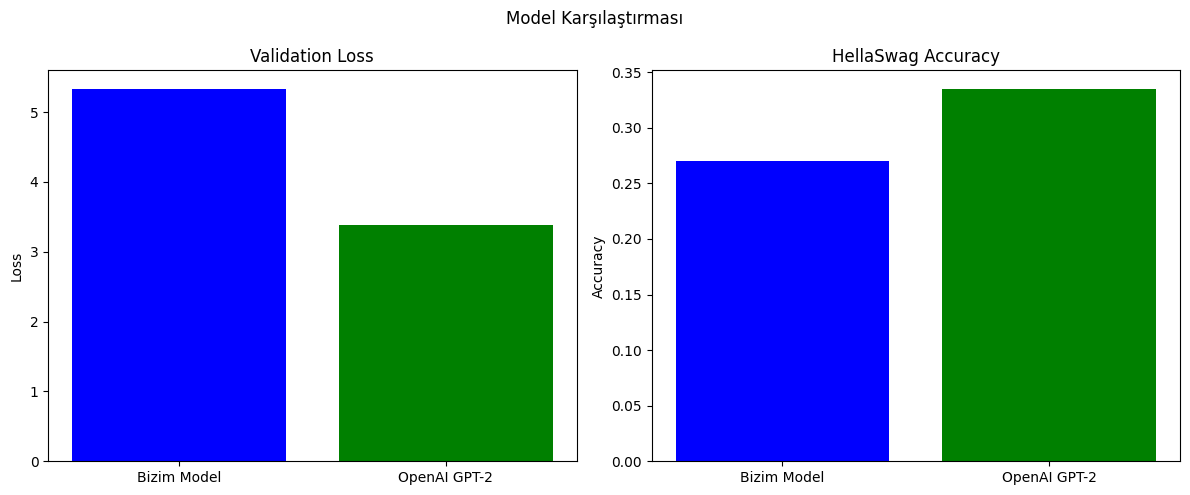

In [12]:
print("OpenAI GPT-2 (124M) yükleniyor...")
openai_model = GPT2LMHeadModel.from_pretrained("gpt2").to(device)
openai_model.eval()

@torch.no_grad()
def estimate_hf_val_loss(hf_model, loader, batches=26):
    hf_model.eval()
    losses = []
    loader.reset()
    for _ in range(batches):
        x, y = loader.next_batch()
        with torch.autocast(device_type=device_type, dtype=torch.float16, enabled=(device_type == "cuda")):
            outputs = hf_model(x)
            logits = outputs.logits
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        losses.append(loss.item())
    return sum(losses) / len(losses)

openai_val_loss = estimate_hf_val_loss(openai_model, val_loader, batches=26)
my_final_val_loss = val_losses[-1] if val_losses else estimate_val_loss(model, val_loader, batches=26)

print(f"Bizim Model Validation Loss: {my_final_val_loss:.4f}")
print(f"OpenAI GPT-2 Validation Loss: {openai_val_loss:.4f}")
print("\nHellaSwag veri seti yükleniyor (Rowan/hellaswag, ilk 1000 örnek)...")
hellaswag_ds = load_dataset("Rowan/hellaswag", split="validation")

def render_example(example):
    ctx = example["ctx"]
    label = int(example["label"])
    endings = example["endings"]
    ctx_tokens = enc.encode_ordinary(ctx)

    tokens_list = []
    labels_list = []
    mask_list = []

    for ending in endings:
        end_tokens = enc.encode_ordinary(" " + ending)
        full_tokens = ctx_tokens + end_tokens
        tokens_list.append(full_tokens[:-1])
        labels_list.append(full_tokens[1:])

        mask = [0] * (len(ctx_tokens) - 1) + [1] * len(end_tokens)
        mask_list.append(mask)

    return tokens_list, labels_list, mask_list, label

@torch.no_grad()
def evaluate_hellaswag(eval_model, max_samples=1000, is_hf=False):
    eval_model.eval()
    correct = 0
    total = 0

    for i, example in enumerate(tqdm(hellaswag_ds, total=max_samples, desc="HellaSwag Evaluated")):
        if i >= max_samples:
            break

        tokens_list, labels_list, mask_list, label = render_example(example)
        losses = []

        for tokens, labels, mask in zip(tokens_list, labels_list, mask_list):
            x = torch.tensor([tokens], dtype=torch.long, device=device)
            y = torch.tensor([labels], dtype=torch.long, device=device)
            m = torch.tensor([mask], dtype=torch.float32, device=device)

            with torch.autocast(device_type=device_type, dtype=torch.float16, enabled=(device_type == "cuda")):
                if is_hf:
                    logits = eval_model(x).logits
                else:
                    logits = eval_model(x)

                shift_logits = logits.reshape(-1, logits.size(-1))
                shift_labels = y.reshape(-1)
                loss_raw = F.cross_entropy(shift_logits, shift_labels, reduction='none')
                loss_masked = (loss_raw * m.reshape(-1)).sum() / m.sum()
                losses.append(loss_masked.item())

        pred = np.argmin(losses)
        if pred == label:
            correct += 1
        total += 1

    acc = correct / total if total > 0 else 0.0
    return acc

my_hellaswag_acc = evaluate_hellaswag(model, max_samples=1000, is_hf=False)
print(f"Bizim Model HellaSwag Doğruluğu: %{my_hellaswag_acc*100:.2f}")

openai_hellaswag_acc = evaluate_hellaswag(openai_model, max_samples=1000, is_hf=True)
print(f"OpenAI GPT-2 HellaSwag Doğruluğu: %{openai_hellaswag_acc*100:.2f}")

del openai_model
gc.collect()
if device_type == "cuda":
    torch.cuda.empty_cache()
print("OpenAI modeli silindi ve CUDA önbelleği temizlendi.")

categories = ['Validation Loss (Lower is better)', 'HellaSwag Accuracy (Higher is better)']
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].bar(['Bizim Model', 'OpenAI GPT-2'], [my_final_val_loss, openai_val_loss], color=['blue', 'green'])
ax[0].set_title('Validation Loss')
ax[0].set_ylabel('Loss')

ax[1].bar(['Bizim Model', 'OpenAI GPT-2'], [my_hellaswag_acc, openai_hellaswag_acc], color=['blue', 'green'])
ax[1].set_title('HellaSwag Accuracy')
ax[1].set_ylabel('Accuracy')

plt.suptitle('Model Karşılaştırması')
plt.tight_layout()
plt.show()

In [13]:
final_path = project_dir / "final_model.pt"
torch.save(model.state_dict(), final_path)
print("Kaydedildi:", final_path)

from google.colab import files
files.download(str(final_path))

Kaydedildi: /content/gpt2_project/final_model.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>